# ED408 — Statistical Machine Learning II Lab
## Experiment 13: Ant Colony Optimisation for shortest-path finding

**Problem.** Find the shortest (fastest) route from a source node to a target node in a road-like network. There are 40 random junctions in the unit square, each linked to its 4 nearest neighbours. An edge's weight is its **travel time**, $w_{ij}=d_{ij}\times c_{ij}$, where $c_{ij}\sim U(1,3)$ is a random congestion factor.

**How an ant walks.** In each iteration $m$ ants start at the source. At node $i$ an ant moves to an unvisited neighbour $j$ with probability
$$p_{ij}=\frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l\in N_i}\tau_{il}^{\alpha}\,\eta_{il}^{\beta}},\qquad \eta_{ij}=1/w_{ij},$$
where $\tau$ is pheromone (what the colony has learned) and $\eta$ is the greedy "visibility". An ant that hits a dead end is discarded.

**Pheromone update.** First pheromone evaporates, $\tau\leftarrow(1-\rho)\tau$. Then ants deposit $Q/L$ on the edges of their path. We compare two classic variants:
* **Ant System (AS)**: *every* ant deposits. This is simple, but mediocre paths that many ants walk can crowd out the best one.
* **MAX–MIN Ant System (MMAS)**: only the iteration-best or the global-best ant deposits, and $\tau$ is kept inside $[\tau_{min},\tau_{max}]$ with $\tau_{max}=1/(\rho L_{best})$ and $\tau_{min}=\tau_{max}/(2n)$. The lower bound keeps every edge possible, so the colony keeps exploring instead of locking in early.

The result is checked against Dijkstra's exact shortest path.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
import heapq

rng = np.random.default_rng(3)
n_nodes, k_nn = 40, 4
pts = rng.uniform(0, 1, (n_nodes, 2))
dist = np.linalg.norm(pts[:, None] - pts[None], axis=-1)
congestion = np.triu(rng.uniform(1, 3, (n_nodes, n_nodes)), 1)
congestion += congestion.T                               # symmetric: same delay both ways

W = np.full((n_nodes, n_nodes), np.inf)                 # weighted adjacency (inf = no edge)
for i in range(n_nodes):
    for j in np.argsort(dist[i])[1:k_nn + 1]:
        W[i, j] = W[j, i] = dist[i, j] * congestion[i, j]
neighbours = [np.where(np.isfinite(W[i]))[0] for i in range(n_nodes)]
edges = np.isfinite(W)

source = int(np.argmin(pts.sum(1)))                      # bottom-left-most node
target = int(np.argmax(pts.sum(1)))                      # top-right-most node
print(f"nodes = {n_nodes}, edges = {edges.sum() // 2}, source = {source}, target = {target}")

def dijkstra(W, s, t):
    best, prev, pq = {s: 0.0}, {}, [(0.0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if u == t: break
        if d > best[u]: continue
        for v in neighbours[u]:
            nd = d + W[u, v]
            if nd < best.get(v, np.inf):
                best[v], prev[v] = nd, int(u)
                heapq.heappush(pq, (nd, int(v)))
    path = [t]
    while path[-1] != s: path.append(prev[path[-1]])
    return path[::-1], best[t]

opt_path, opt_len = dijkstra(W, source, target)
print("Dijkstra shortest path:", opt_path, f" length = {opt_len:.4f}")

nodes = 40, edges = 99, source = 38, target = 7
Dijkstra shortest path: [38, 0, 2, 17, 8, 22, 13, 35, 7]  length = 2.0681


In [2]:
def ant_walk(tau, alpha, beta):
    path, visited, node = [source], {source}, source
    while node != target:
        cand = np.array([j for j in neighbours[node] if j not in visited])
        if len(cand) == 0:
            return None, np.inf                           # dead end: ant is lost
        weights = tau[node, cand] ** alpha * (1 / W[node, cand]) ** beta
        node = int(rng.choice(cand, p=weights / weights.sum()))
        path.append(node); visited.add(node)
    return path, sum(W[a, b] for a, b in zip(path, path[1:]))

def deposit(tau, path, amount):
    for a, b in zip(path, path[1:]):
        tau[a, b] += amount; tau[b, a] += amount

def aco(variant="MMAS", n_ants=20, iters=60, alpha=1.0, beta=1.0, rho=0.1, Q=1.0):
    tau = np.where(edges, 1.0, 0.0)
    best_path, best_len = None, np.inf
    hist = {"best": [], "iter_best": [], "mean": [], "success": [], "on_best": []}
    for it in range(iters):
        walks = [ant_walk(tau, alpha, beta) for _ in range(n_ants)]
        done = [(p, L) for p, L in walks if p is not None]
        it_path, it_len = min(done, key=lambda x: x[1], default=(None, np.inf))   # every ant may get lost
        if it_len < best_len:
            best_path, best_len = it_path, it_len

        tau *= (1 - rho)                                  # evaporation
        if variant == "AS":                               # every successful ant deposits
            for p, L in done:
                deposit(tau, p, Q / L)
        elif best_path is not None:                       # MMAS: alternate iteration-best / global-best
            p, L = (it_path, it_len) if it % 2 == 0 and it_path else (best_path, best_len)
            deposit(tau, p, Q / L)
            tau_max = Q / (rho * best_len)
            tau[edges] = np.clip(tau[edges], tau_max / (2 * n_nodes), tau_max)

        hist["best"].append(best_len); hist["iter_best"].append(it_len)
        hist["mean"].append(np.mean([L for _, L in done]) if done else np.nan)
        hist["success"].append(len(done) / n_ants)
        hist["on_best"].append(np.mean([p == best_path for p, _ in done]) if done else 0.0)
    return best_path, best_len, tau, hist

best_path, best_len, tau, hist = aco("MMAS")
found = np.isclose(hist["best"], opt_len)
print("ACO best path     :", best_path, f" length = {best_len:.4f}")
print("Dijkstra optimum  :", opt_path, f" length = {opt_len:.4f}")
print("ACO found the optimum:", found[-1])
if found[-1]:
    print(f"Optimum first found at iteration {int(np.argmax(found)) + 1}")
print(f"Ants on the best path in the final iteration: {100 * hist['on_best'][-1]:.0f}%")

ACO best path     : [38, 0, 2, 17, 8, 22, 13, 35, 7]  length = 2.0681
Dijkstra optimum  : [38, 0, 2, 17, 8, 22, 13, 35, 7]  length = 2.0681
ACO found the optimum: True
Optimum first found at iteration 15
Ants on the best path in the final iteration: 78%


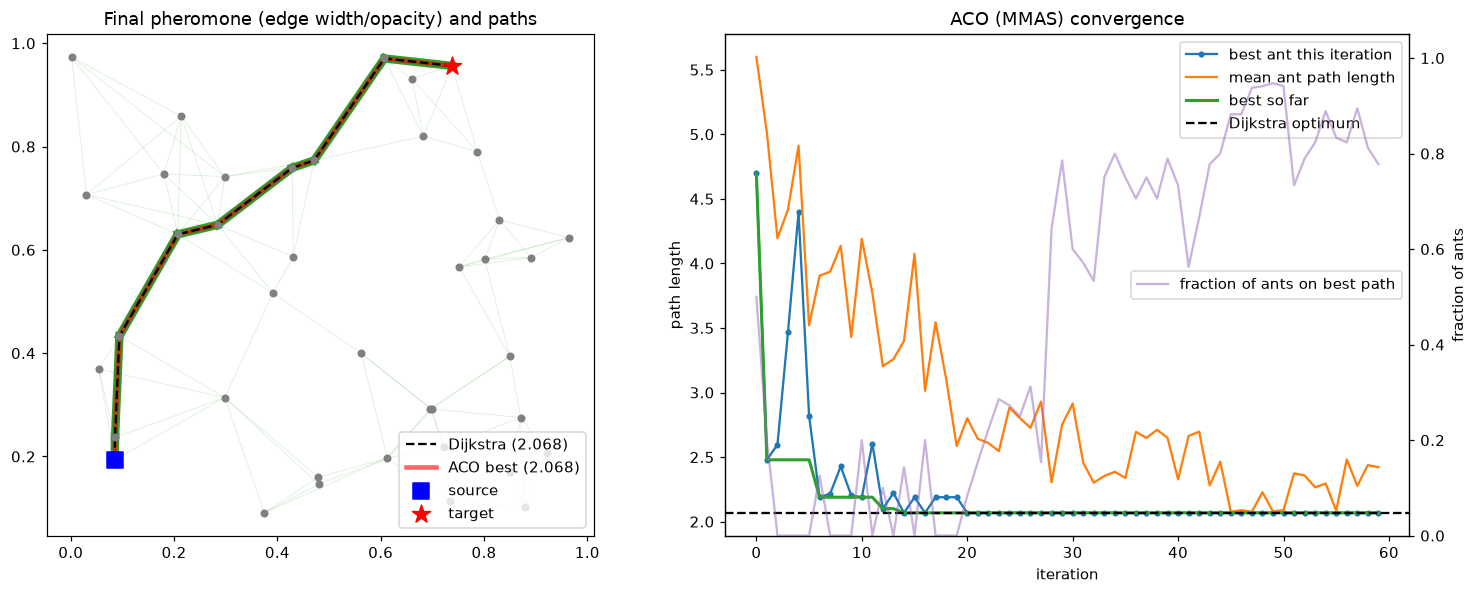

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

tau_max = tau[edges].max()
for i in range(n_nodes):
    for j in neighbours[i]:
        if i < j:
            ax[0].plot(*pts[[i, j]].T, c="tab:green", alpha=0.15 + 0.85 * tau[i, j] / tau_max,
                       lw=0.5 + 5 * tau[i, j] / tau_max, zorder=1)
ax[0].plot(*pts[opt_path].T, "k--", lw=1.5, label=f"Dijkstra ({opt_len:.3f})", zorder=3)
ax[0].plot(*pts[best_path].T, "r-", lw=3, alpha=0.6, label=f"ACO best ({best_len:.3f})", zorder=2)
ax[0].scatter(*pts.T, s=18, c="gray", zorder=4)
ax[0].scatter(*pts[source], s=120, c="b", marker="s", label="source", zorder=5)
ax[0].scatter(*pts[target], s=150, c="r", marker="*", label="target", zorder=5)
ax[0].set(title="Final pheromone (edge width/opacity) and paths", aspect="equal"); ax[0].legend(loc="lower right")

ax[1].plot(hist["iter_best"], "o-", ms=3, label="best ant this iteration")
ax[1].plot(hist["mean"], label="mean ant path length")
ax[1].plot(hist["best"], lw=2, label="best so far")
ax[1].axhline(opt_len, c="k", ls="--", label="Dijkstra optimum")
ax[1].set(xlabel="iteration", ylabel="path length", title="ACO (MMAS) convergence")
ax3 = ax[1].twinx()
ax3.plot(hist["on_best"], c="tab:purple", alpha=0.5, label="fraction of ants on best path")
ax3.set(ylim=(0, 1.05), ylabel="fraction of ants")
ax[1].legend(loc="upper right"); ax3.legend(loc="center right")
plt.tight_layout(); plt.show()

### Ant System vs MMAS, and the effect of $\beta$
With $\beta=0$ the ants ignore edge costs and follow pheromone only. A large $\beta$ makes them greedy, so they take the cheapest next edge even when it leads into a detour. Each setting is run with 10 seeds.

In [4]:
import pandas as pd

rows = []
for variant, beta in [("AS", 1), ("AS", 2), ("MMAS", 0), ("MMAS", 1), ("MMAS", 2), ("MMAS", 3)]:
    found, final, lost = [], [], []
    for s in range(10):
        rng = np.random.default_rng(100 + s)
        _, L, _, h = aco(variant, beta=beta)
        found.append(np.isclose(L, opt_len)); final.append(h["mean"][-1]); lost.append(1 - np.mean(h["success"]))
    rows.append({"variant": variant, "beta": beta, "runs reaching optimum": f"{sum(found)}/10",
                 "mean ant length (last iter)": np.nanmean(final),
                 "ants lost at dead ends": f"{100 * np.mean(lost):.0f}%"})
pd.DataFrame(rows).round(4)

,variant,beta,runs reaching optimum,mean ant length (last iter),ants lost at dead ends
0,AS,1,2/10,2.6134,34%
1,AS,2,0/10,2.4451,22%
2,MMAS,0,3/10,2.3241,35%
3,MMAS,1,9/10,2.1865,34%
4,MMAS,2,6/10,2.4143,35%
5,MMAS,3,1/10,2.3346,27%


**Observations.**
* MMAS finds the exact Dijkstra optimum (length 2.068 over 8 edges), first at iteration 15. By the end about 78% of the ants follow it, and the pheromone map shows a single strong trail from source to target.
* **Why the basic Ant System struggles.** When every ant deposits $Q/L$, the reward is driven by how many ants walk an edge, not by how short their paths are: a 10% longer path earns only 10% less pheromone per ant. AS therefore reinforces whatever route most ants found early, and it reaches the optimum in at most 2 of 10 runs. MMAS lets only the best ant deposit and clamps $\tau$ to $[\tau_{min},\tau_{max}]$. This rewards quality directly and keeps unpromising edges alive, so it reaches the optimum in 9 of 10 runs with $\beta=1$.
* **The heuristic weight β is a trade-off.** With $\beta=0$ the ants are blind to edge costs and wander (3/10). With large $\beta$ (3) they behave like greedy walkers and take the cheapest next edge even when it leads into a detour (1/10). $\beta\approx1$ balances the colony's learned memory against local greed.
* Over a quarter of the ants are lost at dead ends, because the walk forbids revisiting nodes. This wastes samples but does not bias the result, since lost ants deposit nothing.
* On a static graph Dijkstra is exact and much faster. ACO's strengths lie elsewhere: it needs no global view of the graph, and its pheromone can adapt when edge costs change (for example in network routing, AntNet).